# 📘 Notebook 03: The Learning Rate, the Hyperparameter that Matters Most

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **ten minutes** on an ordinary processor. The best learning rate found here (for Adam, on this model and data) is a starting point, not a universal value; the shape of the U-curve and the learning-rate finder work everywhere.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain the **learning rate** as the size of each step of gradient descent
- See on a simple function what **too small**, **just right** and **too large** look like
- Draw the **U-shaped** curve of final accuracy against learning rate, on a **logarithmic** scale
- Run a **learning-rate range test** (the "LR finder") to pick a good value in one short run
- Explain why the best learning rate depends on the **optimiser** and the **batch size**

> **Prerequisites:** [Notebook 02](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/02_epochs_and_early_stopping.ipynb).
>
> 🔭 **Why this notebook matters:** if you can tune only one hyperparameter, tune the learning rate. A wrong value by a factor of ten can make the same network fail to learn at all or crawl for hours; no other single choice has such a large effect.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


## 1. Intuition on a simple function

### Intuition first
Gradient descent walks downhill: at each step it moves the weights against the gradient, and the **learning rate** $\eta$ is the size of the step:

$$w \leftarrow w - \eta \, \frac{\partial \text{loss}}{\partial w}$$

On the simple bowl $f(w) = w^2$, starting at $w = 5$, we try four step sizes.

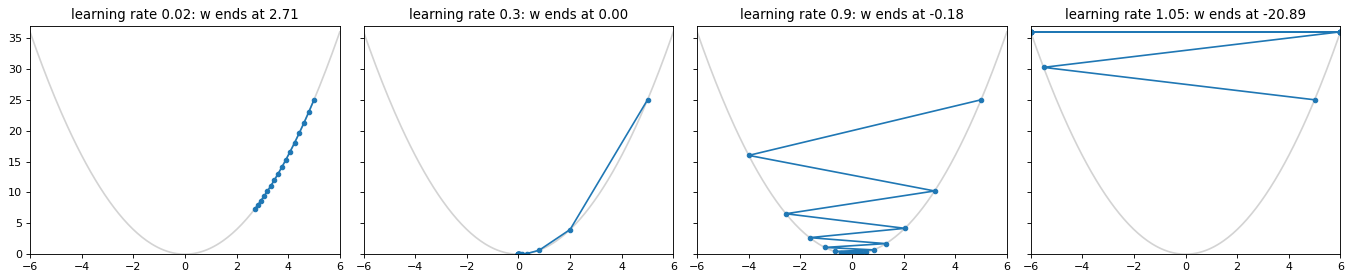

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
grid = np.linspace(-6, 6, 200)
for ax, lr in zip(axes, [0.02, 0.3, 0.9, 1.05]):
    w, path = 5.0, [5.0]
    for _ in range(15):
        w = w - lr * 2 * w          # the gradient of w^2 is 2w
        path.append(w)
    path = np.array(path)
    ax.plot(grid, grid ** 2, color="lightgrey")
    ax.plot(np.clip(path, -6, 6), np.clip(path, -6, 6) ** 2, marker="o", ms=4)
    ax.set_title(f"learning rate {lr}: w ends at {path[-1]:.2f}")
    ax.set_xlim(-6, 6); ax.set_ylim(0, 37)
plt.tight_layout()
plt.show()

**What we see.** Four behaviours on one bowl:
- **0.02, too small:** after 15 steps the weight has only moved from 5 to 2.71: correct direction, painfully slow.
- **0.3, just right:** it reaches the bottom (0.00) in a few steps.
- **0.9, too large but still converging:** every step overshoots to the other side; the weight zig-zags and settles slowly (-0.18).
- **1.05, far too large:** each overshoot is bigger than the last, and the weight runs away (-20.89). This is **divergence**, the source of losses that suddenly become huge or NaN.

Every real network shows the same four behaviours, only in millions of dimensions.

## 2. The U-curve on a real network

We train the same network (one hidden layer of 128 neurons) for 10 epochs with Adam, at learning rates from $10^{-5}$ to $1$, spaced evenly on a **logarithmic** scale.

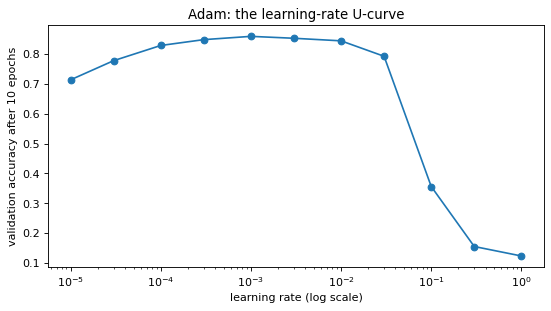

,final train loss,final val acc
learning rate,,
1.000e-05,0.996,0.714
3.000e-05,0.658,0.778
1.000e-04,0.476,0.829
3.000e-04,0.375,0.849
1.000e-03,0.286,0.860
3.000e-03,0.238,0.853
1.000e-02,0.314,0.845
3.000e-02,0.478,0.793
1.000e-01,2.592,0.356


In [3]:
rates = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
sweep = {}
for lr in rates:
    sweep[lr] = fit(make_mlp(hidden=(128,)), epochs=10, lr=lr)
summary = pd.DataFrame({lr: {"final train loss": h["train loss"].iloc[-1], "final val acc": h["val acc"].iloc[-1]} for lr, h in sweep.items()}).T
summary.index.name = "learning rate"
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(summary.index, summary["final val acc"], marker="o")
ax.set_xlabel("learning rate (log scale)"); ax.set_ylabel("validation accuracy after 10 epochs"); ax.set_title("Adam: the learning-rate U-curve")
plt.show()
summary.round(3)

**What we see.** The classic **U-curve** (here an upside-down U, since we plot accuracy):
- From **$10^{-5}$** (71.4%) to **$10^{-3}$** (**86.0%**, the best), accuracy rises: the small rates simply have not learned enough in 10 epochs.
- Between about **$3 	imes 10^{-4}$ and $10^{-2}$** the results are all within about 1.5 points: a wide, comfortable plateau.
- Above **$3 	imes 10^{-2}$**, accuracy collapses: 35.6% at 0.1 and about 12% (barely better than guessing one class in ten) at 0.3 and 1.

The good range spans almost two factors of ten, and Adam's default of 0.001 sits right in the middle. Note how the axis is **logarithmic**: equal steps on it are equal **factors**.

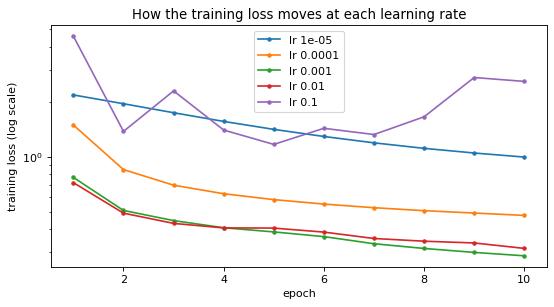

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for lr in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    ax.plot(sweep[lr].index, sweep[lr]["train loss"], marker="o", ms=3, label=f"lr {lr:g}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("training loss (log scale)"); ax.legend()
ax.set_title("How the training loss moves at each learning rate")
plt.show()

**What we see.** At **$10^{-5}$** the training loss crawls down in a straight, slow line; at **$10^{-4}$** it is faster; **$10^{-3}$** and **$10^{-2}$** fall fastest and end lowest (with 0.001 slightly ahead by epoch 10); at **0.1** the loss jumps up and down and ends higher than where it started: the steps are too large to settle anywhere.

## 3. The learning-rate finder

### Intuition first
Sweeping 11 values costs 11 trainings. Leslie Smith proposed a shortcut ([*Cyclical Learning Rates for Training Neural Networks*](https://arxiv.org/abs/1506.01186), 2015): in **one** short run, start with a tiny learning rate and **multiply** it a little after every batch, recording the loss. The loss first barely moves (too small), then falls fast (good range), then explodes (too large). A good choice is a value somewhat **below** the point where the loss falls fastest, about a tenth of where it starts to explode.

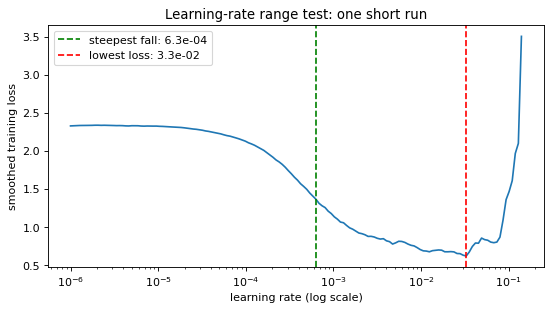

148 batches; suggested range: about 6.3e-04 to 3.3e-03


In [5]:
def lr_finder(model, start=1e-6, end=10, steps=200, batch=128, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=start)
    factor = (end / start) ** (1 / steps)
    lrs, losses, smooth = [], [], None
    for step in range(steps):
        idx = torch.randint(0, len(X_train), (batch,))
        loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()
        lrs.append(opt.param_groups[0]["lr"]); losses.append(smooth)
        if smooth > 4 * min(losses):
            break
        for g in opt.param_groups:
            g["lr"] *= factor
    return np.array(lrs), np.array(losses)

lrs, losses = lr_finder(make_mlp(hidden=(128,)))
steepest = lrs[np.argmin(np.gradient(losses))]
lowest = lrs[np.argmin(losses)]
plt.figure(figsize=(8, 4))
plt.semilogx(lrs, losses)
plt.axvline(steepest, color="green", linestyle="--", label=f"steepest fall: {steepest:.1e}")
plt.axvline(lowest, color="red", linestyle="--", label=f"lowest loss: {lowest:.1e}")
plt.xlabel("learning rate (log scale)"); plt.ylabel("smoothed training loss"); plt.legend()
plt.title("Learning-rate range test: one short run")
plt.show()
low, high = sorted([steepest, lowest / 10])
print(f"{len(lrs)} batches; suggested range: about {low:.1e} to {high:.1e}")

**What we see.** One run of 148 batches (less than two epochs) draws the whole picture: the loss is flat up to about $10^{-5}$, falls fastest around **$6 	imes 10^{-4}$**, reaches its lowest around **$3 	imes 10^{-2}$**, and explodes just above $10^{-1}$. The suggested range, about **$6 	imes 10^{-4}$ to $3 	imes 10^{-3}$**, contains the best value of the full sweep ($10^{-3}$) at a fraction of the cost (Exercise 2 checks it).

## 4. The best learning rate depends on the optimiser and the batch size

In [6]:
rows = {}
for name, opt_name in [("Adam", "adam"), ("SGD", "sgd")]:
    for lr in [1e-4, 1e-3, 1e-2, 1e-1, 3e-1]:
        rows.setdefault(name, {})[lr] = fit(make_mlp(hidden=(128,)), epochs=10, lr=lr, optimizer=opt_name)["val acc"].iloc[-1]
for batch in [32, 512]:
    for lr in [1e-4, 1e-3, 1e-2, 1e-1, 3e-1]:
        rows.setdefault(f"Adam, batch {batch}", {})[lr] = fit(make_mlp(hidden=(128,)), epochs=10, lr=lr, batch=batch)["val acc"].iloc[-1]
table = pd.DataFrame(rows)
table.index.name = "learning rate"
table.round(3)

,Adam,SGD,"Adam, batch 32","Adam, batch 512"
learning rate,,,,
1.000e-04,0.831,0.331,0.848,0.783
1.000e-03,0.860,0.696,0.853,0.852
1.000e-02,0.845,0.804,0.833,0.853
1.000e-01,0.356,0.735,0.117,0.645
3.000e-01,0.155,0.707,0.123,0.141


**What we see.** Three lessons in one table:
- **SGD needs larger learning rates than Adam.** SGD is best at **0.01** (80.4%) and still learns at 0.1 and 0.3, where Adam has collapsed; at Adam's favourite rate of 0.001, SGD reaches only 69.6% in 10 epochs. Using one optimiser's rate with the other is a classic mistake.
- **Larger batches prefer larger rates.** With batch 32, Adam is best at **0.001**; with batch 512 it is just as good at **0.01**, while at 0.0001 it falls to 78.3% (it takes 16 times fewer steps and each one is too timid). Notebook 04 explains why.
- Within the good range the best accuracies are close (85 to 86%), so the learning rate mostly has to be **in the right range**, not exactly right.

## ⚠️ Common pitfalls

- **Searching on a linear scale.** Trying 0.001, 0.002, 0.003 explores almost nothing; learning rates are searched by **factors** (0.0001, 0.001, 0.01...).
- **Copying a learning rate from another optimiser.** Good values for SGD and Adam differ by about a factor of ten or more.
- **Changing the batch size without revisiting the learning rate.** Larger batches usually tolerate, and need, larger rates.
- **Reading the LR finder's minimum as the answer.** At the minimum the loss is about to explode; choose about ten times lower.
- **Blaming the model when the loss is NaN or stuck.** A learning rate that is too large is the most common cause of both.

## ✏️ Exercises

### Exercise 1 (Two hidden layers)
Repeat the U-curve for a network with **two** hidden layers of 128 neurons (rates 1e-4 to 1e-1). Does the best learning rate move?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
deep = {lr: fit(make_mlp(hidden=(128, 128)), epochs=10, lr=lr)["val acc"].iloc[-1] for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]}
print({k: round(v, 3) for k, v in deep.items()})
```

*In our run the best value stayed at 0.001 (85.5%), with 0.0003 and 0.003 within half a point, and accuracy fell steeply above 0.01 (48% at 0.1). For a small change of architecture the best rate usually stays in the same neighbourhood; re-check it whenever the model changes substantially.*
</details>

### Exercise 2 (Trust the finder?)
Train the network for 10 epochs with the two ends of the range the finder suggested. Compare with the best value of the sweep in Section 2.

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for lr in [low, high]:
    print(f"lr {lr:.1e}: val acc {fit(make_mlp(hidden=(128,)), epochs=10, lr=lr)['val acc'].iloc[-1]:.4f}")
print("best of the sweep:", summary["final val acc"].idxmax(), round(summary["final val acc"].max(), 4))
```

*The finder's suggestion lands close to the best value of the full sweep for a fraction of the cost. It is a starting point, refined with a few short trainings around it.*
</details>

## 🔑 Key takeaways

- The **learning rate** sets the step size of gradient descent: too small crawls, too large diverges, in between it learns fast.
- Final accuracy against learning rate is a **U-curve** on a **logarithmic** scale; search by factors of about 3 or 10.
- The **learning-rate finder** locates a good range in one short run.
- The best value depends on the **optimiser** and the **batch size**; re-check it whenever they change.

---
**Next:** *Notebook 04: Batch Size*, how many examples per step, and what that changes.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*